# City Temperature Anomalies and Warming Patterns
This project uses a predefined 27-city panel from Berkeley Earth's **GlobalLandTemperaturesByCity.csv**, distributed in Kaggle's Climate Change Earth Surface Temperature Data. All months from 1951 through 2012 are retained before cleaning. The input has eleven sourced attributes: seven city fields plus four global monthly temperature fields from GlobalTemperatures.csv in the same archive, joined many-to-one by month. Global context is repeated across cities and is not an independent local observation. Current global values are excluded from forecast predictors. Calendar, climatology and lag features are labeled as derived attributes.

[Dataset and license](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) | [Berkeley Earth](https://berkeleyearth.org/data/). Provenance, selection and hashes: `data/provenance.json`. The data card lists CC BY-NC-SA 4.0; the bundled subset is a noncommercial educational adaptation with attribution.

The baseline is each city's calendar-month mean in 1951-1980. Supervised training uses 1981-2000, expanding validation ends in 1992, 1996 and 2000, and final testing uses 2001-2012. Regression predicts the anomaly for a month from information available before it. Classification predicts anomaly above +1 C, a project-defined event rather than a heatwave or global warming threshold. Earlier test-month observations can inform subsequent one-month forecasts; this is rolling evaluation, not a fixed-origin twelve-year forecast. The city panel is not an area-weighted global mean and ends in 2012.


In [3]:
from pathlib import Path  # Build portable file paths for the bundled data and generated outputs.
import json  # Save audit statistics and chosen parameters in a readable format.
import numpy as np  # Use numeric arrays, trigonometry and missing-value markers.
import pandas as pd  # Load and transform the monthly city data as tables.
import matplotlib.pyplot as plt  # Create, label and export figures.
import seaborn as sns  # Plot distributions and relationships using DataFrame columns.
from IPython.display import display  # Render tables directly below the notebook cell.
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, GridSearchCV
SEED=42  # Keep stochastic estimator results reproducible.
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)  # Create a local destination for tables, figures and audit files.
sns.set_theme(style='whitegrid')  # Apply a consistent plot style across deliverables.
def savefig(name):  # Use the same export and display settings for every figure.
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight'); plt.show(); plt.close()  # Fit labels, save the image, display it and release the figure.
raw=pd.read_csv('data/city_temperatures_1951_2012.csv')  # Read the eleven-column joined subset without changing its source file.
df=raw.drop_duplicates().copy()  # Remove exact repeated records while retaining the original DataFrame.
df['date']=pd.to_datetime(df.dt,errors='coerce')  # Parse dates; invalid text becomes NaT and is checked below.
for c in ['AverageTemperature','AverageTemperatureUncertainty']:
    df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan)  # Coerce nonnumeric or nonfinite temperature entries to missing values.
# Flag structurally implausible readings, not legitimate warm or cold extremes.
invalid=~df.AverageTemperature.between(-90,60) & df.AverageTemperature.notna()  # Flag temperatures outside broad physical bounds without deleting real extremes.
df.loc[invalid,'AverageTemperature']=np.nan  # Treat structurally invalid readings as missing outcomes.
assert not df.duplicated(['City','Country','date']).any()  # Require one record for each city-country-month key.
assert df.date.notna().all()  # Stop if any observation month could not be parsed.
df['city_id']=df.City+' | '+df.Country  # Disambiguate cities that share a name across countries.
def coordinate(s):
    return s.str[:-1].astype(float)*np.where(s.str[-1].isin(['S','W']),-1,1)  # Remove the hemisphere suffix and make south/west coordinates negative.
df['latitude']=coordinate(df.Latitude); df['longitude']=coordinate(df.Longitude)  # Convert both coordinate strings into signed numeric degrees.
df['year']=df.date.dt.year; df['month']=df.date.dt.month  # Extract calendar fields for the reference period and chronological splits.
# Climatology uses only 1951-1980: earlier than every supervised training fold.
reference=df[df.year.between(1951,1980)]  # Use only historical observations that precede all model training.
baseline=reference.groupby(['city_id','month']).AverageTemperature.agg(['mean','count']).rename(columns={'mean':'climatology','count':'baseline_count'})  # Estimate a separate normal temperature for each city and calendar month.
assert baseline.baseline_count.min()>=25  # Require adequate historical coverage for every monthly normal.
baseline.to_csv(OUT/'baseline_climatology.csv')  # Export the reference means and counts so anomalies can be audited.
df=df.join(baseline,on=['city_id','month'])  # Attach the matching historical monthly normal to every observation.
df['anomaly']=df.AverageTemperature-df.climatology  # Remove the local seasonal normal; positive values indicate warmer months.
# Ensure shift(1) means the previous calendar month: no compressed time gaps.
df=df.sort_values(['city_id','date']).reset_index(drop=True)  # Order each city chronologically before constructing past-only features.
assert df.groupby('city_id').date.diff().dropna().dt.days.between(28,31).all()  # Check that adjacent rows are consecutive calendar months within each city.
g=df.groupby('city_id')  # Keep lag calculations separate for every city.
df['lag1_anomaly']=g.anomaly.shift(1)  # Use the previous observed month, never the current target month.
df['lag12_anomaly']=g.anomaly.shift(12)  # Represent the same calendar month in the previous year.
df['prior12_mean']=g.anomaly.transform(lambda x:x.shift(1).rolling(12,min_periods=9).mean())  # Shift first, then average past anomalies to prevent target leakage.
df['lag1_uncertainty']=g.AverageTemperatureUncertainty.shift(1)  # Use only previously available measurement uncertainty.
df['month_sin']=np.sin(2*np.pi*df.month/12); df['month_cos']=np.cos(2*np.pi*df.month/12)  # Encode the circular annual cycle so December and January are neighbors.
df['time_years']=df.year-1981+(df.month-1)/12  # Represent long-term time progression with a fractional monthly component.
df['abs_latitude']=df.latitude.abs()  # Represent distance from the equator regardless of hemisphere.
df['hemisphere']=np.where(df.latitude>=0,'North','South')  # Create a descriptive grouping for geographic comparisons.
# Never impute a missing outcome. Predictors are imputed within each training fold.
model=df[df.year.between(1981,2012)&df.anomaly.notna()].sort_values(['date','city_id']).reset_index(drop=True)  # Keep supervised years with an observed target, then sort all cities by month.
model['warm_month']=(model.anomaly>1.0).astype(int)  # Define the positive class using the stated local +1 C anomaly threshold.
train=model[model.year<=2000].copy().reset_index(drop=True)  # Reserve 1981-2000 for estimator fitting and chronological model selection.
test=model[model.year>=2001].copy().reset_index(drop=True)  # Hold 2001-2012 apart for final performance evaluation.
assert train.date.max()<test.date.min()  # Ensure every training month precedes every final test month.
# Same month across all cities belongs to the same fold. No shuffled panel split.
cv=[]  # Store explicit row indices for expanding chronological validation windows.
for end,val_end in [(1988,1992),(1992,1996),(1996,2000)]:  # Expand training history and validate only on the following years.
    ti=np.flatnonzero(train.year.le(end)); vi=np.flatnonzero(train.year.between(end+1,val_end))  # Keep every city from a month on the same side of the fold boundary.
    assert train.iloc[ti].date.max()<train.iloc[vi].date.min()  # Verify that each validation fold contains only future observations.
    cv.append((ti,vi))  # Reuse identical temporal folds for regression and classification tuning.
num=['time_years','month_sin','month_cos','latitude','longitude','abs_latitude',
     'lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']
cat=['city_id']  # Treat city identity as categorical rather than assigning numeric ranks.
features=num+cat  # Select only the documented numeric and categorical predictors.
def preprocessing():  # Return a fresh transformer that each training fold fits independently.
    return ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),  # Impute numeric gaps and standardize using training-fold statistics.
                             ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])  # Encode city membership; unseen categories receive all-zero city indicators.
Xtr,Xte=train[features],test[features]  # Extract predictor tables without including current outcomes.
print('Raw rows:',len(raw),'Cities:',df.city_id.nunique(),'Engineered columns:',len(df.columns))
print('Train: 1981-2000',len(train),'Test: 2001-2012',len(test))
print('Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.')


Raw rows: 20088 Cities: 27 Engineered columns: 29
Train: 1981-2000 6480 Test: 2001-2012 3888
Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.


## Regression and evaluation

,cv_rmse_mean,cv_rmse_sd,test_mse,test_rmse,test_r2
model,,,,,
Mean baseline,1.337610,0.033022,1.794707,1.339667,-0.095533
Linear regression,1.264664,0.027444,1.539251,1.240666,0.060404
Ridge,1.263901,0.026916,1.538991,1.240561,0.060563
Climatology zero,NaN,NaN,2.241673,1.497222,-0.368372
Persistence,NaN,NaN,2.530361,1.590711,-0.544593


Selected using expanding-window CV: Ridge


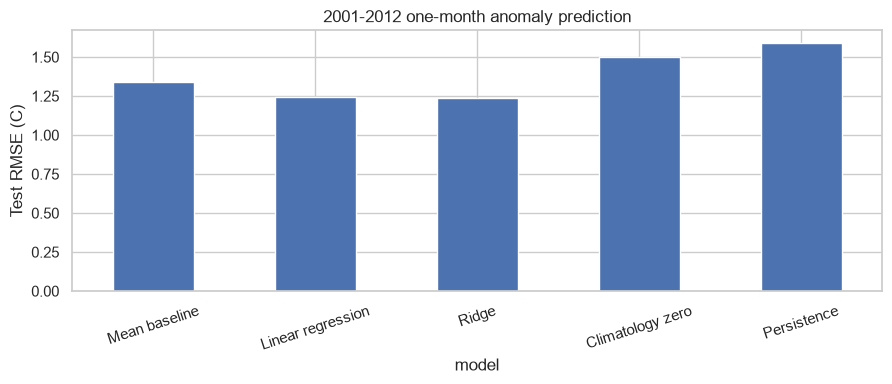

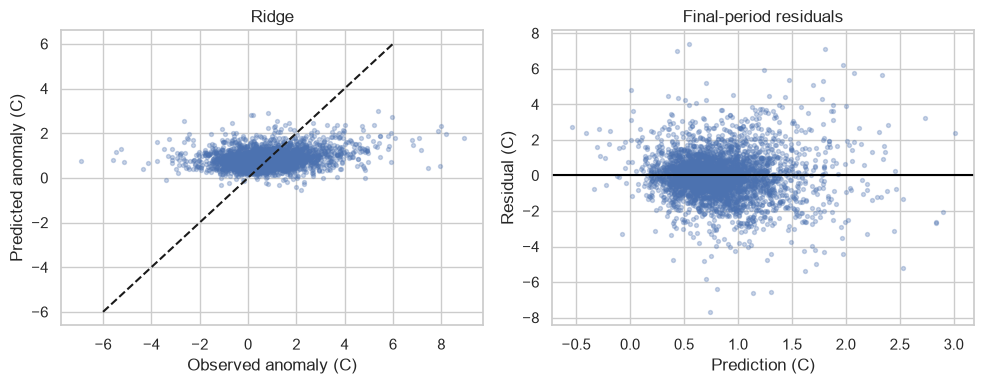

,feature_set,cv_rmse
0,Calendar and location,1.322365
1,Calendar location and past climate,1.263901


,records,mae,mse,rmse
city_id,,,,
Moscow | Russia,144,1.911341,6.656902,2.580097
Chicago | United States,144,1.472923,3.548478,1.883740
Berlin | Germany,144,1.447163,3.519698,1.876086
Toronto | Canada,144,1.421986,3.230546,1.797372
New York | United States,144,1.237344,2.476954,1.573834
Paris | France,144,1.227975,2.470322,1.571726
Los Angeles | United States,144,1.138798,2.104860,1.450814
Rome | Italy,144,1.093252,1.917593,1.384772
Madrid | Spain,144,1.120985,1.789444,1.337701


In [4]:
from sklearn.linear_model import LinearRegression,Ridge  # Import ordinary least squares and L2-regularized regression.
from sklearn.dummy import DummyRegressor  # Provide a fitted-mean reference for evaluating useful prediction.
from sklearn.metrics import mean_squared_error,r2_score
models={'Mean baseline':DummyRegressor(), 'Linear regression':LinearRegression(), 'Ridge':Ridge(alpha=10)}  # Compare the mean baseline with unregularized and regularized linear models.
rows=[];predictions={}  # Collect comparable metrics and retain predictions for residual diagnostics.
for name,est in models.items():  # Evaluate each regression estimator under the same temporal protocol.
    pipe=make_pipeline(preprocessing(),est)  # Fit preprocessing together with the estimator within each fold.
    scores=-cross_val_score(pipe,Xtr,train.anomaly,cv=cv,scoring='neg_root_mean_squared_error')  # Convert negative scorer values back into positive validation RMSE.
    pipe.fit(Xtr,train.anomaly);pred=pipe.predict(Xte);predictions[name]=pred  # Fit on development years and predict the reserved final period.
    rows.append(dict(model=name,cv_rmse_mean=scores.mean(),cv_rmse_sd=scores.std(),  # Summarize fold variability and held-out regression error.
                     test_mse=mean_squared_error(test.anomaly,pred),test_rmse=np.sqrt(mean_squared_error(test.anomaly,pred)),test_r2=r2_score(test.anomaly,pred)))
reg=pd.DataFrame(rows).set_index('model');winner=reg.cv_rmse_mean.idxmin()  # Choose the lowest training-CV RMSE without selecting on test performance.
# Explicit climate baselines: zero anomaly and previous-month anomaly.
for name,pred in [('Climatology zero',np.zeros(len(test))),('Persistence',test.lag1_anomaly.fillna(train.anomaly.mean()).to_numpy())]:  # Add zero-anomaly and previous-month persistence forecasts as climate baselines.
    reg.loc[name]=[np.nan,np.nan,mean_squared_error(test.anomaly,pred),np.sqrt(mean_squared_error(test.anomaly,pred)),r2_score(test.anomaly,pred)]  # Report test metrics; these reference forecasts have no fitted-model CV scores here.
display(reg);print('Selected using expanding-window CV:',winner);reg.to_csv(OUT/'regression_metrics.csv')
reg.test_rmse.plot.bar(figsize=(9,4),rot=18);plt.ylabel('Test RMSE (C)');plt.title('2001-2012 one-month anomaly prediction');savefig('regression_comparison')  # Compare all final-period regression errors in Celsius on one scale.
fig,ax=plt.subplots(1,2,figsize=(10,4));pred=predictions[winner]  # Inspect the predictions from the CV-selected regression model.
ax[0].scatter(test.anomaly,pred,s=8,alpha=.3);ax[0].plot([-6,6],[-6,6],'k--');ax[0].set(xlabel='Observed anomaly (C)',ylabel='Predicted anomaly (C)',title=winner)  # Compare predictions with observations; the dashed diagonal is perfect agreement.
ax[1].scatter(pred,test.anomaly.to_numpy()-pred,s=8,alpha=.3);ax[1].axhline(0,color='black');ax[1].set(xlabel='Prediction (C)',ylabel='Residual (C)',title='Final-period residuals');savefig('regression_residuals')  # Check residual structure around zero to reveal bias and missed extremes.
reg_predictions=test[['date','city_id','anomaly']].copy();reg_predictions['prediction']=pred;reg_predictions.to_csv(OUT/'regression_predictions.csv',index=False)  # Save predictions with their observation month and city for traceability.

# Check whether past-only anomaly features improve CV relative to calendar/location alone.
static_num=[c for c in num if c not in ['lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']]
static_prep=ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),static_num),
                              ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
static_scores=-cross_val_score(make_pipeline(static_prep,Ridge(alpha=10)),Xtr,train.anomaly,cv=cv,scoring='neg_root_mean_squared_error')
ablation=pd.DataFrame({'feature_set':['Calendar and location','Calendar location and past climate'],
                      'cv_rmse':[static_scores.mean(),reg.loc['Ridge','cv_rmse_mean']]})
display(ablation);ablation.to_csv(OUT/'feature_ablation.csv',index=False)  # Assess added features using training CV only.
# Inspect geographic error differences rather than relying solely on pooled metrics.
reg_predictions['absolute_error']=(reg_predictions.anomaly-reg_predictions.prediction).abs()
reg_predictions['squared_error']=(reg_predictions.anomaly-reg_predictions.prediction)**2
city_errors=reg_predictions.groupby('city_id').agg(records=('anomaly','size'),mae=('absolute_error','mean'),mse=('squared_error','mean'))
city_errors['rmse']=np.sqrt(city_errors.mse)
city_errors.to_csv(OUT/'city_errors.csv');display(city_errors.sort_values('rmse',ascending=False))  # Expose uneven local predictive reliability.


## Evaluation and feature rationale
Compare linear regression and ridge against a fitted mean baseline, zero anomaly climatology, and lag-one persistence. Table values include MSE, RMSE and R squared; CV scores come from three expanding chronological windows keeping every city's same month together. Choose by training CV RMSE, not held-out scores. City encoding captures persistent differences, cyclic features represent season, signed coordinates represent location, time represents trend, and past anomalies describe persistence. Current temperature, anomaly, uncertainty and warm label are excluded from predictors. Prior uncertainty is a quality proxy, not an extra climate driver. Low anomaly R squared is possible even when absolute seasonal temperatures would be easy to predict; assess improvement over meaningful baselines.

## Measured findings and reflection

### Regression findings

Training CV selects Ridge: CV RMSE 1.264 C, test RMSE 1.241 C and test R squared 0.061. Ridge CV RMSE changes from 1.322 C with calendar/location to 1.264 C with past climate features. Geographic test RMSE ranges from 0.314 to 2.580 C, so pooled performance does not imply equal local reliability. The low anomaly R squared limits forecasting claims.